# BrushCue Example: Petal Smoke

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/petal_smoke.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/petal-smoke

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


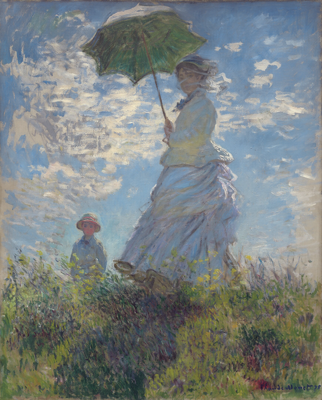

In [1]:
import io
from PIL import Image

import brushcue as bc


@bc.brushcue_fn
def apply(input_image, strength):
    graded = input_image.color_transformer_shader(
        "let l = clamp(input.x, 0.0, 1.0);\nlet shadow = 1.0 - smoothstep(0.12, 0.67, l);\nlet petal = smoothstep(0.015, 0.09, input.y);\nlet ab = input.yz * (0.84 + 0.22 * petal) + vec2f(0.023, -0.025) * shadow + vec2f(0.018, -0.008) * petal;\nlet tone = l + 0.055 * (1.0 - l) * (1.0 - l);\nreturn vec4f(mix(input.xyz, vec3f(tone, ab), amount), input.w);",
        "",
        bc.ColorRepresentation.oklab_a(),
        bc.ColorRepresentation.oklab_a(),
        bc.Dictionary.create().add("amount", strength),
    )
    sampling = graded.color_transformer_shader(
        "return vec4f(input.rgb * input.a, input.a);",
        "",
        bc.ColorRepresentation.srgb(),
        bc.ColorRepresentation.srgb(),
        bc.Dictionary.create(),
    )
    bounds = input_image.bounds()
    reference_scale = (bounds.width().min(bounds.height()) / 1000.0).max(0.001)
    radius = (9.0 * reference_scale).max(0.5)
    return sampling.spacial_effect_shader(
        "let lo = image_bounds.xy + vec2f(0.5);\nlet hi = image_bounds.zw - vec2f(0.5);\nlet center_sample = sample(clamp(position, lo, hi));\nlet center = vec4f(center_sample.rgb / max(center_sample.a, 0.00001), center_sample.a);\nif (center.a <= 0.0) { return center; }\nvar total = vec3f(0.0);\nvar weight = 0.0;\nfor (var y = -1; y <= 1; y = y + 1) {\n  for (var x = -1; x <= 1; x = x + 1) {\n    let offset = vec2f(f32(x), f32(y));\n    let raw = sample(clamp(position + offset * radius, lo, hi));\n    let c = vec4f(raw.rgb / max(raw.a, 0.00001), raw.a);\n    let saturation = max(c.r, max(c.g, c.b)) - min(c.r, min(c.g, c.b));\n    let w = c.a * smoothstep(0.025, 0.20, saturation);\n    total += c.rgb * w; weight += w;\n  }\n}\nlet local = total / max(weight, 0.00001);\nlet saturation = max(center.r, max(center.g, center.b)) - min(center.r, min(center.g, center.b));\nlet spread = smoothstep(0.02, 0.18, saturation) * min(weight, 1.0);\nreturn vec4f(mix(center.rgb, local, spread * 0.40 * amount), center.a);",
        "",
        radius,
        bc.Dictionary.create()
        .add("amount", strength)
        .add("radius", radius)
        .add("image_bounds", bounds)
        .add("reference_scale", reference_scale),
        bc.ColorRepresentation.srgb(),
    ).crop(bounds)


strength = 1.0
input_image = bc.Composition.monet_women_with_parasol()
graph = apply(input_image, strength)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
